<h1 align="center"> Assignment 1 </h1>
<h1 align="center">Agile Software Development</h1>
<h1 align="center">NYC_Airbnb_Data_Analysis_Sprint1</h1>

**Students:**

Baljeet Kaur,

Iheanacho, Precious

Martins Ronqui Miyajima, Paula

Zhu, Yaqun


**Project Overview**

This project is developed as part of the CPSC-620-3 Agile Software Development Take-Home Assessment.

The goal is to build a Python-based tool that reads, cleans, and summarizes NYC Airbnb listing data.

The project follows Agile development practices using GitHub and GitHub Projects.

**Sprint Goal**

Develop a functional Python-based NYC Airbnb Data Summary Tool that cleans and processes Airbnb listing data and generates meaningful summaries of listing prices, room types, neighbourhoods, and availability.

<h1 align="center"> 1.1 Import Libraries and Load Dataset </h1>


In [1]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from src.data_cleaning import load_data, clean_data, get_data_summary
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
data = load_data("data/Airbnb_NYC.csv")
cleaned_data = clean_data(data)
summary = get_data_summary(cleaned_data)
summary

{'total_listings': 41749,
 'average_price': 153.88,
 'median_price': 107.0,
 'room_types': {'Entire home/apt': 21709,
  'Private room': 19055,
  'Shared room': 985}}

<h1 align="center"> 1.2 Code Implementation and Initial Data Analysis - Zhu, Yaqun </h1>

**This part was developed and implemented by Zhu, Yaqun, in the first task of the Sprint**

In [7]:
# Display data cleaning results
print("=== NYC Airbnb Data Summary Tool ===")

print("\nOriginal listings:", len(data))
print("Cleaned listings:", len(cleaned_data))
print("Removed records:", len(data) - len(cleaned_data))

print("\n=== Summary Statistics ===")
print("Total listings:", summary["total_listings"])
print("Average price:", summary["average_price"])
print("Median price:", summary["median_price"])

print("\n=== Room Type Distribution ===")
for room_type, count in summary["room_types"].items():
    print(f"{room_type}: {count}")

=== NYC Airbnb Data Summary Tool ===

Original listings: 42336
Cleaned listings: 41672
Removed records: 664

=== Summary Statistics ===
Total listings: 41749
Average price: 153.88
Median price: 107.0

=== Room Type Distribution ===
Entire home/apt: 21709
Private room: 19055
Shared room: 985


<h1 align="center"> 1.3 Code Implementation and Initial Data Analysis - Miyajima, Paula </h1>
<h1 align="center"> Task 2 of the Sprint </h1>


**This part was developed and implemented by Miyajima, Paula, in the second task of the Sprint**

**Note**: It was necessary in Task 2 of the Sprint to analyze the variable availability_365, because it was noticed that this variable has missing values that were not addressed by Task 1 of the Sprint.

# 1.3.A - Checking Missing Values and Most Frequency Values of the variable availability_365

In [8]:
adjust_availability = cleaned_data["availability_365"]

missing_count = adjust_availability.isna().sum()
total_count = len(cleaned_data)

print("Variable availability_365")
print("Data type:", adjust_availability.dtype)
print("Missing values:", missing_count)
print("\nMost frequent values:")
print(adjust_availability.value_counts(dropna=False).head(20))

missing_percentage = (missing_count / total_count) * 100
print(f"Percentage of Missing Values in availability_365: {missing_percentage:.2f}%")

Variable availability_365
Data type: Int64
Missing values: 0

Most frequent values:
availability_365
0      14887
365     1097
364      424
1        357
89       309
5        293
3        263
2        246
179      246
90       244
6        209
4        208
363      207
342      196
8        195
7        193
188      192
88       177
180      174
311      173
Name: count, dtype: Int64
Percentage of Missing Values in availability_365: 0.00%


## 1.3.A - Convert availability_365 from string to numeric and Remove the Missing Values

In [9]:
availability_clean = pd.to_numeric(cleaned_data["availability_365"].astype("string").str.replace(r"\s*days\s*$", "", regex=True)
        .str.strip(),errors="coerce")

missing_count = availability_clean.isna().sum()

cleaned_data["availability_365"] = availability_clean

cleaned_data = cleaned_data.dropna(
    subset=["availability_365"]).copy()

print("Outliers removed:", missing_count)
print("After removing outliers:", len(cleaned_data))
print("Missing availability values:", cleaned_data["availability_365"].isna().sum())
print("Data type:", cleaned_data["availability_365"].dtype)

Outliers removed: 0
After removing outliers: 41672
Missing availability values: 0
Data type: Int64


## 1.3.A - Remove listings with invalid availability values above 365 days

In [10]:
cleaned_data = cleaned_data[
    cleaned_data["availability_365"] <= 365].copy()

print("Total Records remaining:", len(cleaned_data))
print("Availability Maximum per Year in variable availability_365:",cleaned_data["availability_365"].max())

Total Records remaining: 41668
Availability Maximum per Year in variable availability_365: 365


## 1.3.A - Interpretation of the Results

When doing Task 2 of the Sprint, it was noticed that the variable availability_365 had not been handled in Task 1 of the Sprint because there were 77 missing values for this variable.

Since the number of missing values in this variable was only 0.18% of the total dataset, it was decided to remove these records given the small proportion. After the exclusion, the total number of data points was 41,672 listings. It's important to clarify that the variable was converted to numeric format.

An important point is that since this variable represents the number of days an ad is available per year, numbers above 365 were excluded, since a year doesn't have more than 365 days.  After deleting 4 records in this situation, 41,668 records remained.

# 1.3.B - Checking Outliers in the variable "minimum_nights" 

When doing Task 2 of the Exploratory Data Analysis sprint, it was noticed that there were unrealistic values in the "minimum_nights" variable, including values like 1250, which are inconsistent with the intended focus on short-term and seasonal accommodation. For this reason, it was necessary to revisit Task 1 of the sprint and clean this variable so that the data analysis would be more concrete and realistic.

## 1.3.B - Checking for extreme values in minimum_nights (above 90)

In [11]:
print("Maximum Number in Variable minimum_nights:", cleaned_data["minimum_nights"].max())

print("\nTotal listings that require a minimum stay of more than 90 days")
display(cleaned_data.loc[cleaned_data["minimum_nights"] > 90,["id", "name", "neighbourhood", "room_type", "minimum_nights"]
    ].sort_values("minimum_nights", ascending=False).head(5))

print("\nTotal listings that require a minimum stay of more than 90 days:",(cleaned_data["minimum_nights"] > 90).sum())

Maximum Number in Variable minimum_nights: 1250.0

Total listings that require a minimum stay of more than 90 days


,id,name,neighbourhood,room_type,minimum_nights
17111,4204302,Prime W. Village location 1 bdrm,Greenwich Village,Entire home/apt,1250.0
30046,12387018,Modern 1BR in Downtown Manhattan,Lower East Side,Entire home/apt,1188.0
37678,19779749,Private Room in Sunny South Harlem Apt,Harlem,Private room,1125.0
31042,1615764,NaN,Battery Park City,Entire home/apt,1000.0
13383,20990053,Beautiful place in Brooklyn! #2,Williamsburg,Private room,999.0



Total listings that require a minimum stay of more than 90 days: 169


## 1.3.B - Boxplot for visualizing outliers

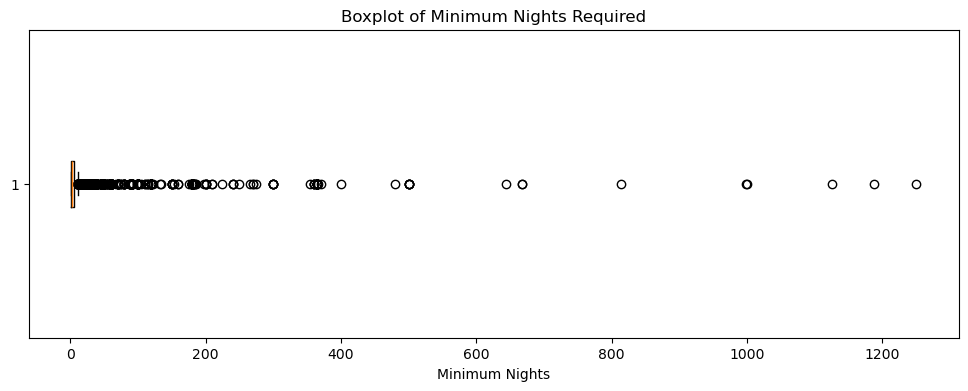

In [12]:
plt.figure(figsize=(12, 4))
plt.boxplot(cleaned_data["minimum_nights"].dropna(), vert=False)
plt.xlabel("Minimum Nights")
plt.title("Boxplot of Minimum Nights Required")
plt.show()

## 1.3.B - Remove Outliers in "minimum_nights"

In [13]:
initial_count = len(cleaned_data)

cleaned_data = cleaned_data[cleaned_data["minimum_nights"] <= 90].copy()

removed_count = initial_count - len(cleaned_data)

print("Before removing outliers:", initial_count)
print("Removed:", removed_count)
print("After removing outliers:", len(cleaned_data))

Before removing outliers: 41668
Removed: 169
After removing outliers: 41499


## 1.3.B - Interpretation - Remove Outliers in "minimum_nights"

According to Airbnb, Inc. (2026), “Our business is seasonal, reflecting typical global travel patterns.”  According to the New York City Office of Special Enforcement (n.d.), “Short-term rental refers to any rental within a home or apartment for a period shorter than 30 days.”

There are outliers in the 'minimum_nights' variable, as 169 records require a minimum stay exceeding 90 days, with the maximum reaching 1,250 nights.

This seems inconsistent with the focus on tourism and seasonal accommodation, such as vacation or winter stays.

Therefore, considering that these extreme values fall outside the scope of the analysis, 169 listings, representing less than 0.50% of the dataset, were excluded.  After deleting 169 records in this situation, 41,499 records remained.

Regarding outliers, NIST/SEMATECH (n.d.) states that “If it can be determined that an outlying point is in fact erroneous, then the outlying value should be deleted from the analysis.”

# 1.3.C - Checking Outliers in variable "Price" 

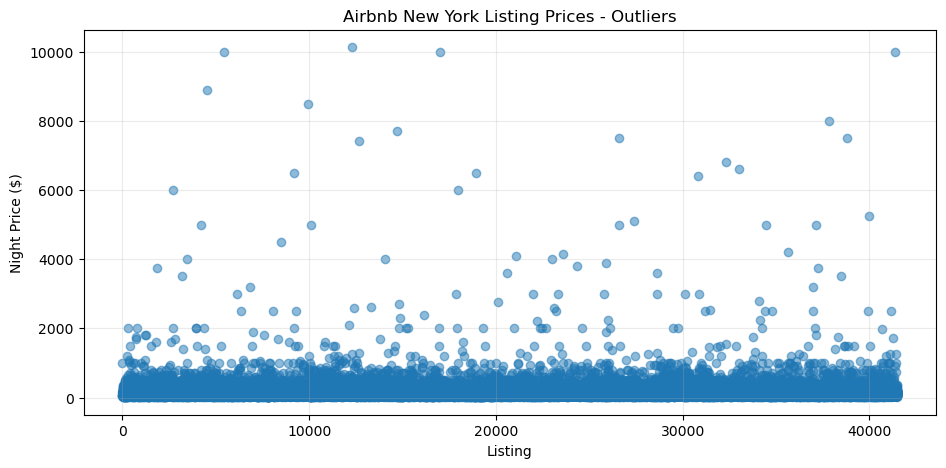

In [14]:
# 1.3.c - Scatter Plot to Identify Outliers in Variable Price

plt.figure(figsize=(11, 5))

plt.scatter(range(len(cleaned_data)),cleaned_data["price"],alpha=0.5)

plt.title("Airbnb New York Listing Prices - Outliers")
plt.xlabel("Listing")
plt.ylabel("Night Price ($)")
plt.grid(True, alpha=0.25)
plt.savefig( f"Scatter Plot to Identify Outliers in Variable Price.png",dpi=250,bbox_inches="tight")
plt.show()

# 1.3.C - Check the Distribution of Outliers in "Price"

In [15]:
price_percentiles = cleaned_data["price"].quantile([0.95, 0.975, 0.99, 0.995, 0.999])

print("Price percentiles:")
print(price_percentiles)

print("\nNumber of listings above each candidate threshold:")

for percentile in [0.99, 0.995]:
    threshold = cleaned_data["price"].quantile(percentile)
    count = (cleaned_data["price"] > threshold).sum()
    percentage = count / len(cleaned_data) * 100

    print(f"{percentile:.1%} percentile: "f"${threshold:.2f} | "f"{count} listings ({percentage:.2f}%)")
    print("\nHighest listing prices:")
print(cleaned_data["price"].sort_values(ascending=False).head(15).to_list())


Price percentiles:
0.950     358.0
0.975     500.0
0.990    794.02
0.995    1000.0
0.999    3100.4
Name: price, dtype: Float64

Number of listings above each candidate threshold:
99.0% percentile: $794.02 | 415 listings (1.00%)

Highest listing prices:
99.5% percentile: $1000.00 | 199 listings (0.48%)

Highest listing prices:
[10128.0, 10000.0, 9999.0, 9999.0, 8899.0, 8500.0, 8000.0, 7703.0, 7500.0, 7500.0, 7406.0, 6800.0, 6596.0, 6500.0, 6500.0]


# 1.3.C - Keeping the Outliers in the "Price" Variable

This data analysis identified the existence of Price Outliers in the listings.

However, after research, it was decided to keep the Outliers since studies on the rental topic indicate that characteristics and location are important factors influencing Airbnb prices. 

Bernardi and Guidolin (2023) state that “the results confirm that property and service attributes play a significant role in determining rental prices”. In the same line, Deboosere et al. (2019) explain that “locational factors – above all, transit accessibility to jobs – and neighbourhood variation have a large impact on both price per night and monthly revenue”.

Therefore, it was decided to keep the findings of high prices in this analysis because high prices can reflect legitimate differences in property characteristics and location, and not just an error.

<h1 align="center"> 2. Data Analysis and Summary Statistics </h1>
<h1 align="center"> Task 2 of the Sprint </h1>


**This part was developed and implemented by Miyajima, Paula, in the second task of the Sprint**

1. Which neighborhoods have the average highest average Airbnb prices?

2. Which neighborhoods have the average lowest average prices?

3. How many listings are there in each analyzed neighborhood?

4. Analysis of the type of accommodation.

5. Analysis of how many days the ad is available per year.

6. Descriptive statistics of numerical variables.

8. Identification and treatment of extreme values in the minimum_nights variable.

9. Identification of the neighborhoods with the highest number of listings.

# 2.A - Descriptive Statistics

In [16]:
numeric_columns = ["price","minimum_nights","number_of_reviews","availability_365"]

descriptive_stats = cleaned_data[numeric_columns].describe().round(2)

display(descriptive_stats)

,price,minimum_nights,number_of_reviews,availability_365
count,41499.0,41499.00,41499.00,41499.0
mean,153.02,6.11,23.59,112.5
std,244.77,9.84,49.46,131.46
min,10.0,1.00,0.00,0.0
25%,69.0,1.00,1.00,0.0
50%,107.0,2.00,5.00,45.0
75%,175.0,5.00,24.00,226.0
max,10128.0,90.00,2208.00,365.0


# 2.A  - Interpretation

From the data extraction shown above, it's important to highlight information such as (i) the average nightly price was  153.02, while the median was $107.00, suggesting a right-skewed price distribution since the average is almost 50% higher than the median, (ii) the minimum stays averaged 6.11 nights, compared with a median of 2 nights, and (iii) listings received an average of 23.59 reviews, while the median was only 5.  Average availability was 112.50 days per year, while the median was 45 days.  All these differences suggest substantial variability and possible extreme values in the dataset that need to be addressed.

## 2.B - Group the Listings by Neighborhood

## 2. C - Exclude neighborhoods with few listings to reduce the risk of highlighting a neighborhood based on a very small sample

## 2. D - Group the Average and Median Prices

It’s necessary to clarify that any and all neighborhoods with fewer than 50 listings were removed from the dataset.

In [17]:
# 2.B - Group the Listings by Neighborhood

reduce_neighbourhood = (cleaned_data.groupby("neighbourhood").agg(total_listings=("price", "count"),average_price=("price", "mean")).reset_index())

#2. D - Exclude neighborhoods with few listings to reduce the risk of highlighting a neighborhood based on a very small sample
reduce_neighbourhood = reduce_neighbourhood[reduce_neighbourhood["total_listings"] >= 50].copy()

#2. C - Group the Average and Median Prices
reduce_neighbourhood["average_price"] = (reduce_neighbourhood["average_price"].round(2))
neighbourhoods_more_expensive = reduce_neighbourhood.sort_values(by="average_price",ascending=False).head(12)

print("The 12 Most Expensive Neighbourhoods in New York")
display(neighbourhoods_more_expensive)

The 12 Most Expensive Neighbourhoods in New York


,neighbourhood,total_listings,average_price
218,Tribeca,148,467.45
11,Battery Park City,57,398.32
85,Flatiron District,62,346.95
161,NoHo,61,305.23
104,Greenwich Village,337,300.5
199,SoHo,293,292.54
144,Midtown,1303,283.43
234,West Village,668,265.6
40,Chelsea,922,254.8
212,Theater District,237,237.96


# 2.B - 2.C - 2.D - Interpretation of the results

The results show that Tribeca had the highest average listing price  469.61, followed by Battery Park City 398.32. These findings indicate that neighbourhoods with the highest average listing prices do not necessarily have the largest numbers of listings, as the most expensive neighbourhoods are not necessarily the ones with the highest listing counts on Airbnb.

# 2.E - Scatter Plot Chart - 12 Neighborhoods with the Most Expensive Average Daily price

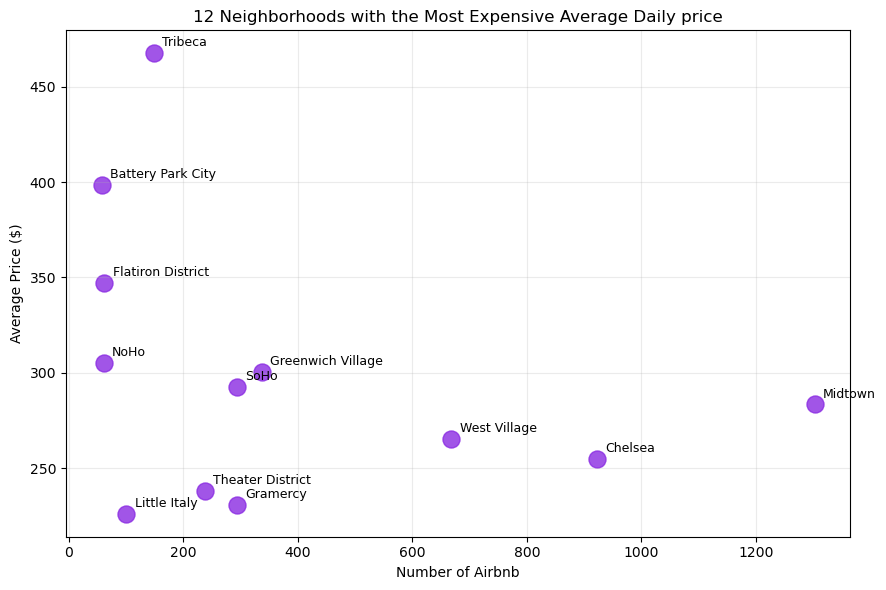

In [18]:
top_12 = reduce_neighbourhood.sort_values( by="average_price", ascending=False).head(12)

plt.figure(figsize=(9, 6))
plt.scatter(top_12["total_listings"],top_12["average_price"],s=150,color="#8A2BE2",alpha=0.8)

for _, row in top_12.iterrows():
    plt.annotate(row["neighbourhood"],(row["total_listings"], row["average_price"]),xytext=(6, 5),textcoords="offset points",fontsize=9)

plt.xlabel("Number of Airbnb")
plt.ylabel("Average Price ($)")
plt.title("12 Neighborhoods with the Most Expensive Average Daily price")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig( f"Scatter Plot Chart - 12 Neighborhoods with the Most Expensive Average Daily pri.png",dpi=250,bbox_inches="tight")
plt.show()

# 2.F - Scatter Plot Chart - 12 Neighborhoods with the Least Average Daily Price

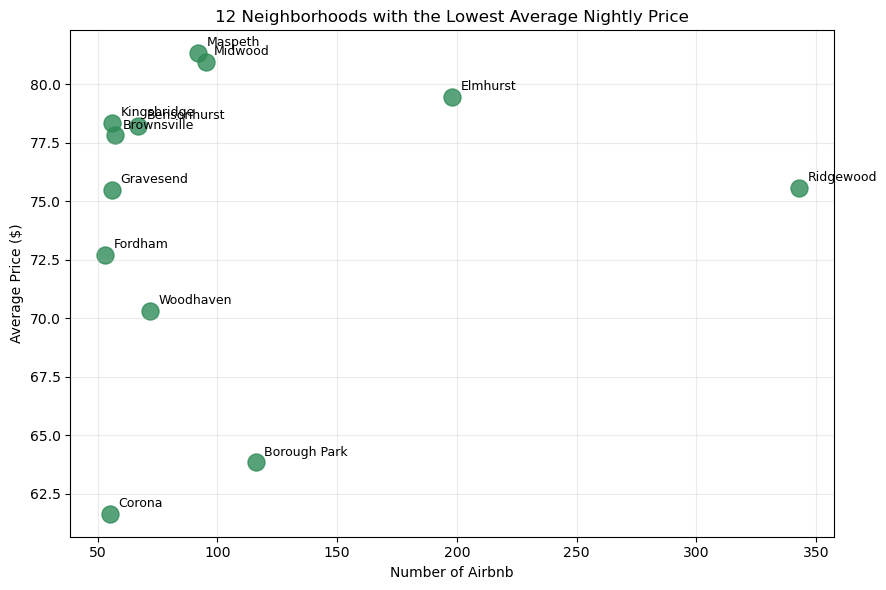

In [19]:
bottom_12 = reduce_neighbourhood.sort_values(by="average_price", ascending=True).head(12)

plt.figure(figsize=(9, 6))

plt.scatter(bottom_12["total_listings"],bottom_12["average_price"],s=150,color="#2E8B57",alpha=0.8)

for _, row in bottom_12.iterrows():
    plt.annotate(row["neighbourhood"],(row["total_listings"], row["average_price"]),xytext=(6, 5),textcoords="offset points",fontsize=9)

plt.xlabel("Number of Airbnb")
plt.ylabel("Average Price ($)")
plt.title("12 Neighborhoods with the Lowest Average Nightly Price")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig( f"12 Neighborhoods with the Lowest Average Daily Price.png",dpi=250,bbox_inches="tight")
plt.show()

# 2.G - Average Price and Number of Listings by Room Type

In [20]:
type_of_accomodation = (cleaned_data.groupby("room_type").agg(total_listings=("price", "count"),
        average_price=("price", "mean")).reset_index())

type_of_accomodation["average_price"] = (type_of_accomodation["average_price"].round(2))
type_of_accomodation = type_of_accomodation.sort_values(by="average_price", ascending=False)

display(type_of_accomodation)
print("Total of Accomodation Listings:", type_of_accomodation["total_listings"].sum())

,room_type,total_listings,average_price
0,Entire home/apt,21566,212.66
1,Private room,18958,89.4
2,Shared room,975,70.97


Total of Accomodation Listings: 41499


## 2.G - Interpretation

It can be seen that Entire Home (non-shared) listings had the highest average price, averaging 212.87, and also the largest number of listings. Private rooms had a much lower average price of 90.97 and also have fewer listings than Entire Homes. Shared rooms, on the other hand, have a much smaller number of listings and an average daily rate of $70.76, which shows that Entire Homes and Private Rooms dominate the Airbnb market in New York.

## 2.H - Analysis of how many days each type of ad stays available

In [21]:
days_availability = (cleaned_data.groupby("room_type").agg(average_availability=("availability_365", "mean"),
        total_listings=("availability_365", "count")    ).reset_index())

days_availability["average_availability"] = (
    days_availability["average_availability"].round(2))

days_availability = days_availability.sort_values(by="average_availability",ascending=False)

display(days_availability)

print("Total listings included in the analysis:",days_availability["total_listings"].sum())

,room_type,average_availability,total_listings
2,Shared room,160.14,975
1,Private room,111.49,18958
0,Entire home/apt,111.22,21566


Total listings included in the analysis: 41499


# 2.I - Check the Number of Listings by Neighbourhood

In [22]:
neighbourhood_listings = (cleaned_data.groupby("neighbourhood").size().reset_index(name="total_listings")
    .sort_values(by="total_listings", ascending=False))

print("Top 5 neighbourhoods by number of listings in Airbnb NY:")
display(neighbourhood_listings.head(5))

Top 5 neighbourhoods by number of listings in Airbnb NY:


,neighbourhood,total_listings
239,Williamsburg,3324
18,Bedford-Stuyvesant,3143
107,Harlem,2269
33,Bushwick,2097
225,Upper West Side,1694


# 2.I - Interpretation

There are neighborhoods that have a lot of listings, like Williamsburg with 3,313 listings, and Bedford-Stuyvesant in second place with 3,136 listings.

<h1 align="center"> Refferences </h1>

Airbnb, Inc. (2026). Annual report (Form 10-K), fiscal year 2025. U.S. Securities and Exchange Commission. https://www.sec.gov/Archives/edgar/data/1559720/000155972026000004/abnb-20251231.htm

Bernardi, M., & Guidolin, M. (2023). The determinants of Airbnb prices in New York City: A spatial quantile regression approach. Journal of the Royal Statistical Society Series C: Applied Statistics, 72(1), 104–143. https://doi.org/10.1093/jrsssc/qlad001

Deboosere, R., Kerrigan, D., Wachsmuth, D., & El-Geneidy, A. (2019). Location, location and professionalization: A multilevel hedonic analysis of Airbnb listing prices and revenue. Regional Studies, Regional Science, 6(1), 143–156. https://doi.org/10.1080/21681376.2019.1592699

New York City Office of Special Enforcement. (n.d.). FAQ for prospective hosts. https://www.nyc.gov/site/specialenforcement/faq/faq-for-prospective-hosts.page

NIST/SEMATECH. (n.d.). Detection of outliers. e-Handbook of Statistical Methods. https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm